# Multi-Target Tracking using Real-World examples

This notebook analyzes data from field tests and tests the MTT methods using this data.
For this two datasets were used:
1. A dataset with a single zebra
2. A dataset with a herd of elefants and later a herd of zebras


**Notice**  
This code is set up to use the zebra dataset.  
If another dataset should be analyzed please go through the code and comment/uncomment the accoring sections.  
By default commands that save the figure are commented.  

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime
from collections import defaultdict

# third-party imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display
import tqdm

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils
import multi_target_tracking as mtt

# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])
importlib.reload(sys.modules['multi_target_tracking'])


# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu
import utils.sensor_sim as ss
import multi_target_tracking as mtt

Murty algorithm not available. Please install the murty package when using MHT tracking.


In [2]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

In [3]:
script_name = "07_real_data"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)
# Log to file and console
logger.info("Notebook started - Multi-Target Tracking using Real-World examples")

INFO: Notebook started - Multi-Target Tracking using Real-World examples


## Single Drone Tracking

### Get Rosbag

In [4]:
## CONFIGURATION
# BAG_PATH = os.path.join(project_root, 'data/0411_zebras_2025-04-11_13_50_40_1.bag') # single zebra
BAG_PATH = os.path.join(project_root, 'data/0404_1elephants1_2025-04-04_11_10_26_1.bag') # elephants / zebra herd

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
rbu.display_rosbag_info(bag_reader)

#################### Topics and message counts: ####################
Topic: /machine_1/command
    Message type: TopicInfo(msgtype='uav_msgs/msg/uav_pose', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data="# A representation of 3D position, 3D orientation and 3D velocity and in free space, composed of position and orientation.\n# Point position (north,east,down)\n# Point velocity (north,east,down)\n# Quaternion orientation (x,y,z,w -- 0,0,0,1 = X(front)-> north, Y(right)-> east, Z(bottom))\n# float64[100] covariance diagonal 10x10 matrix, column order: posN,posE,posD,velN,velE,velD,Qx,Qy,Qz,Qw\n# Point rotation (roll,pitch,yaw)\n# float64 thrust (power setting -1 <= thrust <= +1 , negative thrust=engine off)\n# int32 flightmode (TODO: to be defined later)\n# NOTE: To include complete covariance information, a float32[100] Covariance (10x10 matrix) would be needed as well. Transferring that with every update might limit bandwidth significantly.\n\n\nHeader header\n

### Analyse Amount of Detections

In [5]:
bag_topic = "/machine_1/object_detections/amount"
num_detections = []
time = []
starttime = -1
with bag_reader:
    connections = [x for x in bag_reader.connections if x.topic == bag_topic]
    for connection, timestamp, rawdata in bag_reader.messages(connections=connections):
        msg = bag_reader.deserialize(rawdata, connection.msgtype)
        num_detections.append(msg.data)
        time.append(timestamp / 1e9)  # Convert nanoseconds to seconds
        if starttime == -1:
            starttime = timestamp / 1e9
        time[len(time)-1] -= starttime
# logger.info(f"Number of detections per timestamp: {num_detections}")
# logger.info(f"Timestamps: {time}")

INFO: Average detections per frame: 1.20
INFO: Maximum detections in a frame: 9
INFO: Minimum detections in a frame: 0


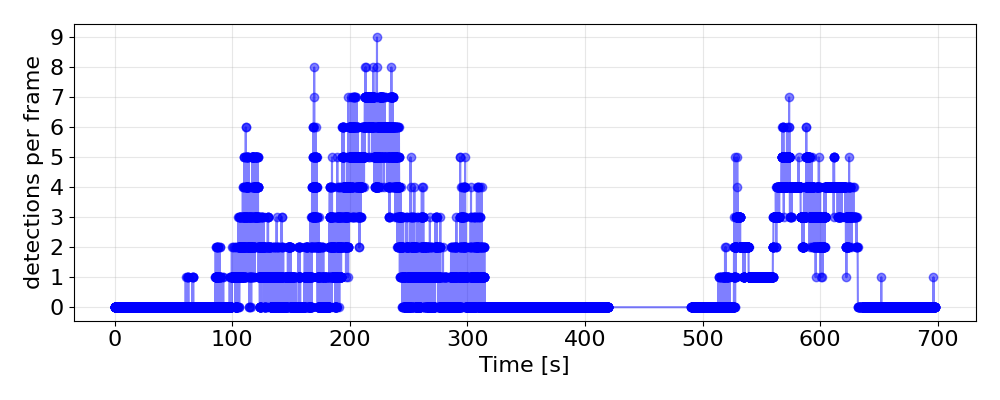

In [6]:
## Analyze the number of detections per frame

# Calculate some statistics
avg_detections = np.mean(num_detections)
max_detections = np.max(num_detections)
min_detections = np.min(num_detections)
logger.info(f"Average detections per frame: {avg_detections:.2f}")
logger.info(f"Maximum detections in a frame: {max_detections}")
logger.info(f"Minimum detections in a frame: {min_detections}")

# Plot the number of detections per frame
plt.figure(figsize=(10, 4))
plt.plot(time, num_detections, marker='o', linestyle='-', color='b', alpha=0.5)
# plt.title("Number of Detections per Frame", fontsize=24)
plt.xlabel("Time [s]")
plt.ylabel("detections per frame")

# Set integer ticks on y-axis
max_y = max(num_detections) + 1
y_ticks = np.arange(0, max_y, 1, dtype=int)
plt.yticks(y_ticks)

# Add a horizontal line for the average
# plt.axhline(y=avg_detections, color='r', linestyle='--', label=f'Avg: {avg_detections:.2f}')

# Add grid and legend
plt.grid(True, alpha=0.3)
plt.tight_layout()

# custom axis limits
# plt.xlim((470, 630))
# plt.ylim((-0.5, 7.5))

In [7]:
# Save the plot (uncomment the line corresponding to your dataset)
# plt.savefig(os.path.join(PLOTS_DIR, "detections_per_frame_zebra.svg"), dpi=600, bbox_inches='tight')
# plt.savefig(os.path.join(PLOTS_DIR, "detections_per_frame_elephants.svg"), dpi=600, bbox_inches='tight')
# plt.savefig(os.path.join(PLOTS_DIR, "detections_per_frame_real_zebra_herd.svg"), dpi=600, bbox_inches='tight')

In [8]:
# get the number of detections for the selected time range
start, end = (560, 630)
start_index = np.searchsorted(time, start)
end_index = np.searchsorted(time, end)

# calculate in percent how many frames have 0, 1, 2, 3, 4 detections
detection_counts = defaultdict(int)
for count in num_detections[start_index:end_index]:
    detection_counts[count] += 1
# Calculate total frames in the range
total_frames = end_index - start_index
# Calculate percentages
detection_percentages = {k: (v / total_frames) * 100 for k, v in detection_counts.items()}
# Log the detection percentages
logger.info(f"Detection percentages in the range {start}-{end} seconds:")
for count, percentage in sorted(detection_percentages.items()):
    logger.info(f"{count} detections: {percentage:.2f}%")

INFO: Detection percentages in the range 560-630 seconds:
INFO: 1 detections: 0.26%
INFO: 2 detections: 9.51%
INFO: 3 detections: 27.90%
INFO: 4 detections: 52.49%
INFO: 5 detections: 9.13%
INFO: 6 detections: 0.65%
INFO: 7 detections: 0.06%


### Load Data

In [9]:
## DATA EXTRACTION
# Define topics to analyze
topics = [
    "/machine_1/object_detections/projected_to_world"
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data

INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


In [10]:
projected_df = topic_data["/machine_1/object_detections/projected_to_world"]
# set the start time to 0
projected_df['time'] -= starttime

## cut the data to the time range of interest
# uncomment the line corresponding to your dataset
# start_time, end_time = (projected_df['time'].min(), projected_df['time'].max())  # full range
# start_time, end_time = (200, 420)  # single zebra
# start_time, end_time = (200, 240)  # elephants
start_time, end_time = (420, 630)  # zebras herd in elephant dataset

projected_df = projected_df[(projected_df['time'] >= start_time) & (projected_df['time'] <= end_time)]

# somehow the data timestamps do not match the timestamps of the number of detections

In [11]:
# # plot gt with projected measurements
# fig_proj = pu.plot_xyz_over_time(projected_df, label="Projected Measurements", marker='x')
# handles, labels = fig_proj.axes[0].get_legend_handles_labels()
# # fig_proj.legend(handles, labels, loc='upper right')
# # fig_proj.suptitle("Projected Measurements")
# fig_proj.set_size_inches(12, 6) # set different size for ppt presentation
# fig_proj.tight_layout(rect=[0, 0, 1, 0.95])
# plt.show()

In [12]:
# Save the plot (uncomment the line corresponding to your dataset)
# plt.savefig(os.path.join(PLOTS_DIR, "projected_meas_zebra.svg"), dpi=600, bbox_inches='tight')
# plt.savefig(os.path.join(PLOTS_DIR, "projected_meas_elephants.svg"), dpi=600, bbox_inches='tight')

Next the data is brought into the format that the MTT toolbox uses.  
It is necessary to order the projections by time, since the MTT algorithms always use all detections of one frame. For this a custom ros message and topic were created in the WildCap simulation. However the field test data does not provide these topics. Since it was not possible to rerun the rosbags and create that data due to time constraints, the projected data was grouped by timestamp to simulate measurement groups that belong to one frame.

In [13]:
proj_time, proj_measurements = dfu.dataframe_to_measurements(projected_df)

# Group measurements by timestamp
measurements_by_time = defaultdict(list)
for time, meas in zip(proj_time, proj_measurements):
    # Round timestamp to nearest millisecond to handle small timestamp differences
    # within the same frame
    rounded_time = round(time * 28) / 28
    measurements_by_time[rounded_time].append(meas)

# Convert to list of measurement groups sorted by timestamp
data_drone_id = 1 # ID of the drone is 1 because it is from machine 1
proj_data = []
for timestamp in sorted(measurements_by_time.keys()):
    meas = np.array(measurements_by_time[timestamp], dtype=object)
    proj_data.append((timestamp, meas, data_drone_id))

# Log info about the grouped measurements
logger.info(f"Grouped {len(proj_measurements)} measurements into {len(proj_data)} frames")
logger.info(f"Average measurements per frame: {len(proj_measurements) / len(proj_data):.2f}")

# analyze covariances
results = dfu.analyze_measurement_covariance(proj_measurements)
print(results)

INFO: Grouped 6796 measurements into 2451 frames
INFO: Average measurements per frame: 2.77


               mean       min        max    median
std_x      2.398607  1.726901  10.444195  2.146692
std_y      2.790084  1.525231  16.111504  1.795873
std_z      2.368019  1.750899   6.672234  2.099671
std_total  4.492886  2.979671  17.437176  3.490393


### Tracking

In [14]:
# Initialize the tracker components
gater = mtt.MahalanobisGater()
mh_likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

# Initialize the tracker with the components and configuration
tracker = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=mh_likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
)

# Evaluate the tracker using the grouped measurements
logger.info("Starting tracking using position measurements")
for measurements in tqdm.tqdm(proj_data, total=len(proj_data), desc="Tracking Real Data"):
    tracker.evaluate(measurements)
tracker.tracks = tracker.tracks
print(f"Number of tracks: {len(tracker.tracks)}")

INFO: Starting tracking using position measurements


Tracking Real Data: 100%|██████████| 2451/2451 [00:08<00:00, 286.58it/s]

Number of tracks: 16


In [15]:
## Extract confirmed tracks
confirmed_tracks = [track for track in tracker.tracks if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in tracker.tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
results = [dfu.track_to_dataframe(track) for track in confirmed_tracks]

Number of confirmed tracks: 16
Number of active tracks in the end: 8


### Plotting

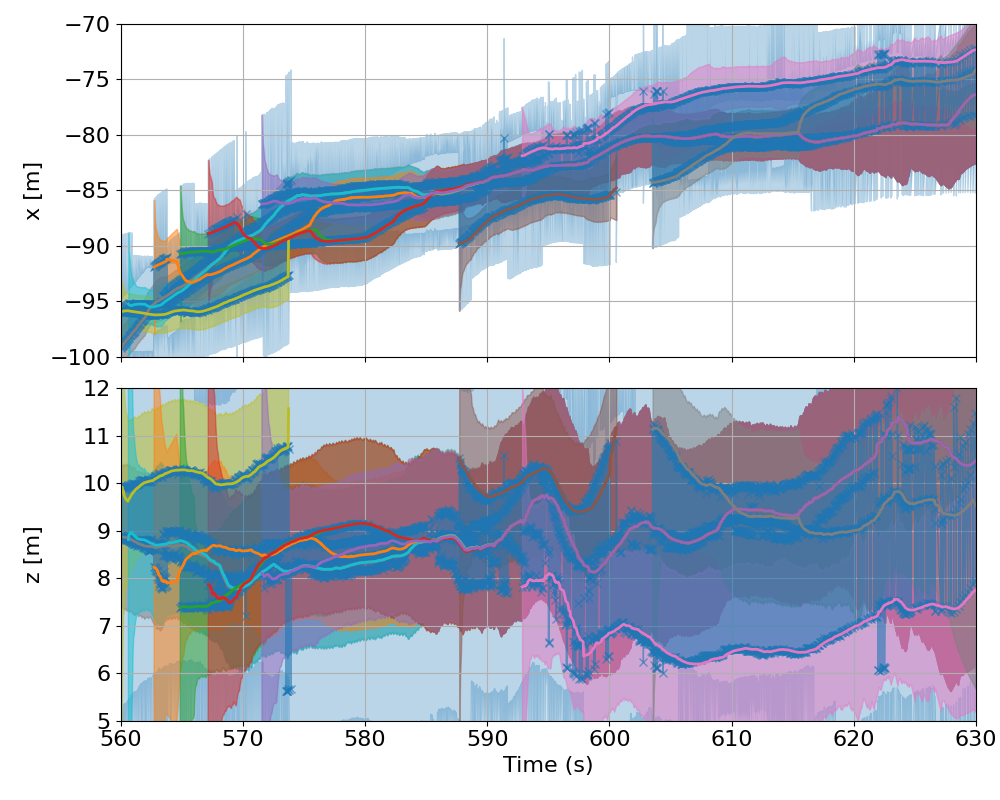

In [16]:
coords = ['x', 'z']  # Coordinates to plot
## pos tracker plot with gt and measurements
# fig_proj_tracks = pu.plot_xyz_over_time(projected_df, label="projected data", alpha=0.15, marker='x')
fig_proj_tracks = pu.plot_xyz_over_time(projected_df, label="projected data", alpha=0.6, marker='x', show_uncertainty=True, coords=coords)

tab_colors = ['tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
for i, track_df in enumerate(results):
    pu.plot_xyz_over_time(track_df, fig=fig_proj_tracks, label=f"Track {i+1}", linewidth=2.0, show_uncertainty=True, coords=coords, color=tab_colors[i % len(tab_colors)])
    # pu.plot_xyz_over_time(track_df, fig=fig_proj_tracks, label=f"Track {i+1}", linewidth=1.5, linestyle=linestyles[i])

handles, labels = fig_proj_tracks.axes[0].get_legend_handles_labels()
# fig_proj_tracks.legend(handles, labels, loc='upper right')
# fig_proj_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.925))
# fig_proj_tracks.suptitle("JPDA position Tracking - GT with Tracks")
fig_proj_tracks.set_size_inches(10, 8)
fig_proj_tracks.tight_layout(rect=[0, 0, 1.0, 1.0])
fig_proj_tracks.align_ylabels()

# custom y-axis limits
# zebra
# fig_proj_tracks.axes[0].set_ylim((88, 152))
# fig_proj_tracks.axes[1].set_ylim((-102, -50))
# fig_proj_tracks.axes[2].set_ylim((-10, 6))
# elephants
# fig_proj_tracks.axes[0].set_ylim((26, 38))
# fig_proj_tracks.axes[1].set_ylim((398, 420))
# fig_proj_tracks.axes[2].set_ylim((5, 10))
# multi_zebra
fig_proj_tracks.axes[0].set_ylim((-100, -70))
# fig_proj_tracks.axes[1].set_ylim((168, 202))
fig_proj_tracks.axes[1].set_ylim((5, 12))
# custom x-axis limits
for ax in fig_proj_tracks.axes:
    ax.set_xlim((560, 630))

In [17]:
# fig_proj_tracks.savefig(os.path.join(PLOTS_DIR, "proj_tracking_mn_gate1.5_real_zebra.svg"), dpi=600, bbox_inches='tight')
# fig_proj_tracks.savefig(os.path.join(PLOTS_DIR, "proj_tracking_sl_gate1.5_elephants_200-225.svg"), dpi=600, bbox_inches='tight')
# fig_proj_tracks.savefig(os.path.join(PLOTS_DIR, "proj_tracking_mn_gate1.5_zebra_herd_xz.svg"), dpi=600, bbox_inches='tight')

#### animate the targets

In [18]:
# pu.animate_2d_targets(results)

## Multi drone tracking

### Get Rosbags

In [19]:
## CONFIGURATION
BAG_PATH1 = os.path.join(project_root, 'data/0406_1donkey1_2025-04-06_08_22_54_1.bag')
BAG_PATH2 = os.path.join(project_root, 'data/0406_1donkey1_2025-04-06_08_23_10_2.bag')

## ROSBAG READER
# Load the bag file
bag_path1 = Path(BAG_PATH1)
if not bag_path1.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path1}")
bag_reader1 = rbu.load_rosbag(bag_path1)
rbu.display_rosbag_info(bag_reader1)
bag_path2 = Path(BAG_PATH2)
if not bag_path2.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path2}")
bag_reader2 = rbu.load_rosbag(bag_path2)
rbu.display_rosbag_info(bag_reader2)
bag_readers = [bag_reader1, bag_reader2]

#################### Topics and message counts: ####################
Topic: /machine_1/command
    Message type: TopicInfo(msgtype='uav_msgs/msg/uav_pose', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data="# A representation of 3D position, 3D orientation and 3D velocity and in free space, composed of position and orientation.\n# Point position (north,east,down)\n# Point velocity (north,east,down)\n# Quaternion orientation (x,y,z,w -- 0,0,0,1 = X(front)-> north, Y(right)-> east, Z(bottom))\n# float64[100] covariance diagonal 10x10 matrix, column order: posN,posE,posD,velN,velE,velD,Qx,Qy,Qz,Qw\n# Point rotation (roll,pitch,yaw)\n# float64 thrust (power setting -1 <= thrust <= +1 , negative thrust=engine off)\n# int32 flightmode (TODO: to be defined later)\n# NOTE: To include complete covariance information, a float32[100] Covariance (10x10 matrix) would be needed as well. Transferring that with every update might limit bandwidth significantly.\n\n\nHeader header\n

### Analyse Amount of Detections

In [20]:
all_detections = []
all_timestamps = []
starttime = -1
for i, bag_reader in enumerate(bag_readers, start=1):
    bag_topic = f"/machine_{i}/object_detections/amount"
    logger.info(f"Processing data of bag topic {bag_topic}")
    num_detections = []
    time = []
    with bag_reader:
        connections = [x for x in bag_reader.connections if x.topic == bag_topic]
        for connection, timestamp, rawdata in bag_reader.messages(connections=connections):
            msg = bag_reader.deserialize(rawdata, connection.msgtype)
            num_detections.append(msg.data)
            time.append(timestamp / 1e9)  # Convert nanoseconds to seconds
            if starttime == -1:
                starttime = timestamp / 1e9
            time[len(time)-1] -= starttime
    all_detections.append(num_detections)
    all_timestamps.append(time)
    # logger.info(f"Number of detections per timestamp: {num_detections}")
    # logger.info(f"Timestamps: {time}")

INFO: Processing data of bag topic /machine_1/object_detections/amount
INFO: Processing data of bag topic /machine_2/object_detections/amount


(500.0, 1030.0)

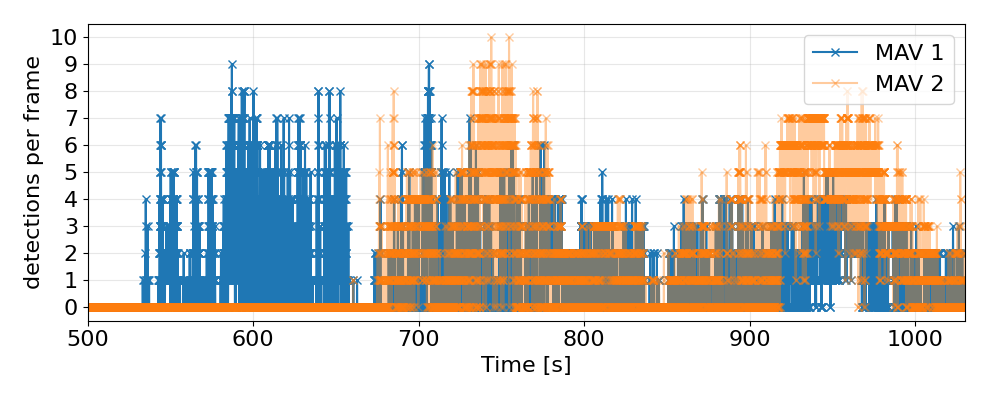

In [21]:
# plot the number of detections
## Analyze the number of detections per frame
# Plot the number of detections per frame
plt.figure(figsize=(10, 4))
alphas = [1.0, 0.4]
for i, (time, num_detections, alpha) in enumerate(zip(all_timestamps, all_detections, alphas), start=1):
    plt.plot(time, num_detections, marker='x', linestyle='-', alpha=alpha, label=f"MAV {i}")
# plt.title("Number of Detections per Frame", fontsize=24)
plt.legend(loc='upper right')
plt.xlabel("Time [s]")
plt.ylabel("detections per frame")

# Set integer ticks on y-axis
max_y = max(num_detections) + 1
y_ticks = np.arange(0, max_y, 1, dtype=int)
plt.yticks(y_ticks)

# Add a horizontal line for the average
# plt.axhline(y=avg_detections, color='r', linestyle='--', label=f'Avg: {avg_detections:.2f}')

# Add grid and legend
plt.grid(True, alpha=0.3)
plt.tight_layout()

# custom axis limits
plt.xlim((500, 1030))
# plt.ylim((-0.5, 7.5))

In [22]:
# plt.savefig(os.path.join(PLOTS_DIR, "detections_per_frame_donkey.svg"), dpi=600, bbox_inches='tight')

In [23]:
# get the number of detections for 200-400 seconds
start, end = (900, 1000)
start_index = np.searchsorted(time, start)
end_index = np.searchsorted(time, end)

# calculate in percent how many frames have 0, 1, 2, 3, 4 detections
for i, num_detections in enumerate(all_detections):
    logger.info(f"Calculate statistic for machine_{i}")
    detection_counts = defaultdict(int)
    for count in num_detections[start_index:end_index]:
        detection_counts[count] += 1
    # Calculate total frames in the range
    total_frames = end_index - start_index
    # Calculate percentages
    detection_percentages = {k: (v / total_frames) * 100 for k, v in detection_counts.items()}
    # Log the detection percentages
    logger.info(f"Detection percentages in the range {start}-{end} seconds:")
    for count, percentage in sorted(detection_percentages.items()):
        logger.info(f"{count} detections: {percentage:.2f}%")

INFO: Calculate statistic for machine_0
INFO: Detection percentages in the range 900-1000 seconds:
INFO: 0 detections: 27.14%
INFO: 1 detections: 21.65%
INFO: 2 detections: 20.48%
INFO: 3 detections: 25.08%
INFO: 4 detections: 5.49%
INFO: 5 detections: 0.17%
INFO: Calculate statistic for machine_1
INFO: Detection percentages in the range 900-1000 seconds:
INFO: 0 detections: 12.23%
INFO: 1 detections: 6.53%
INFO: 2 detections: 7.96%
INFO: 3 detections: 12.02%
INFO: 4 detections: 13.78%
INFO: 5 detections: 19.97%
INFO: 6 detections: 18.38%
INFO: 7 detections: 8.88%
INFO: 8 detections: 0.25%


### Load Data

In [24]:
## DATA EXTRACTION
# Extract and process data
topic_data = {}
for i, bag_reader in enumerate(bag_readers, start=1):
    topic = f"/machine_{i}/object_detections/projected_to_world"
    data = rbu.create_df_from_bag(bag_reader, topic)
    data['time'] -= starttime  # set the start time to 0
    print(data['time'][0])
    topic_data[topic] = data

INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


533.3045902252197


INFO: Processing topic: '/machine_2/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'


660.332946062088


In [25]:
all_proj_detections = []
start_time, end_time = (850, 1030)  # time range of interest for both bags

for i, (topic, projected_df) in enumerate(topic_data.items(), start=1):
    logger.info(f"Processing topic {topic} for machine {i}")
    # cut the data to the time range of interest
    projected_df = projected_df[(projected_df['time'] >= start_time) & (projected_df['time'] <= end_time)]
    
    proj_time, proj_measurements = dfu.dataframe_to_measurements(projected_df)

    # Group measurements by timestamp
    measurements_by_time = defaultdict(list)
    for time, meas in zip(proj_time, proj_measurements):
        # Round timestamp to nearest millisecond to handle small timestamp differences
        # within the same frame
        rounded_time = round(time * 30) / 30
        measurements_by_time[rounded_time].append(meas)

    # Convert to list of measurement groups sorted by timestamp
    data_drone_id = i # ID of the drone is 1 because it is from machine 1
    proj_data = []
    for timestamp in sorted(measurements_by_time.keys()):
        meas = np.array(measurements_by_time[timestamp], dtype=object)
        proj_data.append((timestamp, meas, data_drone_id))
    all_proj_detections.extend(proj_data)

    # Log info about the grouped measurements
    logger.info(f"Grouped {len(proj_measurements)} measurements into {len(proj_data)} frames")
    logger.info(f"Average measurements per frame: {len(proj_measurements) / len(proj_data):.2f}")

    # analyze covariances
    results = dfu.analyze_measurement_covariance(proj_measurements)
    print(results)

all_proj_detections.sort(key=lambda x: x[0])

# get the max number of measurements in a frame
max_measurements = max(len(meas) for _, meas, _ in all_proj_detections)
logger.info(f"Max number of measurements in a frame: {max_measurements}")
print(starttime)

INFO: Processing topic /machine_1/object_detections/projected_to_world for machine 1
INFO: Grouped 5319 measurements into 2614 frames
INFO: Average measurements per frame: 2.03
INFO: Processing topic /machine_2/object_detections/projected_to_world for machine 2


               mean       min       max    median
std_x      1.744396  1.545349  4.287277  1.682746
std_y      1.754214  1.462055  7.750768  1.556810
std_z      1.718428  1.504245  5.285441  1.636683
std_total  3.026716  2.605467  9.739048  2.815364


INFO: Grouped 10829 measurements into 2873 frames
INFO: Average measurements per frame: 3.77
INFO: Max number of measurements in a frame: 13


               mean       min        max    median
std_x      1.835578  1.603334   4.398206  1.705839
std_y      1.934299  1.477941   9.107405  1.601535
std_z      1.814293  1.560857   4.791683  1.670857
std_total  3.240519  2.702201  10.798135  2.882771
1743920587.863352


### Tracking

In [26]:
# Initialize the tracker components
gater = mtt.MahalanobisGater()
mh_likelihood = mtt.MahalanobisLikelihood()
filter = mtt.KFTrack()
score_logic = mtt.ScoreLogic()
mn_logic = mtt.MNLogic()

# Initialize the tracker with the components and configuration
jpda = mtt.JPDATracker(
    filter_obj=filter,
    gater=gater,
    likelihood=mh_likelihood,
    track_logic=mn_logic,
    drone_id=None, # offset estimation for single drone tracking
)

# tracker = mtt.DistributedJPDA(
#     tracker=tracker,
#     gater=gater,
#     likelihood=mh_likelihood,
#     track_logic=score_logic,
#     drone_id=None,  # offset estimation for single drone tracking
# )

tracker = mtt.SynchronizedDistributedTracker(
    tracker=jpda,
    num_drones=2,  # number of drones in the dataset
    buffer_size=30,
)

# Evaluate the tracker using the grouped measurements
logger.info("Starting tracking using position measurements")
for (time, meas, drone_id) in tqdm.tqdm(all_proj_detections, total=len(all_proj_detections), desc="Tracking Real Data"):
    tracker.add_measurements(time, meas, drone_id)
print(f"Number of tracks: {len(tracker.tracks)}")

# to df for plotting
data_df = dfu.measurements_to_dataframe(np.array([m[0] for _, m, _ in all_proj_detections]),
                                        np.array([t for t, _, _ in all_proj_detections]),)

INFO: Starting tracking using position measurements
Tracking Real Data:   0%|          | 0/5487 [00:00<?, ?it/s]INFO: Wait limit exceeded. Processing data without all drones. 


INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
Tracking Real Data:   6%|▋         | 348/5487 [00:00<00:08, 575.93it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
Tracking Real Data:   9%|▉         | 512/5487 [00:00<00:07, 637.12it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
Tracking Real Data:  12%|█▏        | 683/5487 [00:01<00:07, 680.48it/s]INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
INFO: Wait limit exceeded. Processing data without all drones. 
Tracking Real Data:  14%|█▍        | 755/5487 [00:01<00:07, 667.43it/s]INFO: Wait l

Number of tracks: 13


In [27]:
## Extract confirmed tracks
confirmed_tracks = [track for track in tracker.tracks if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
# Uncomment the following lines to print detailed information about each confirmed track
# for track in confirmed_tracks:
#     print(f"Track ID: {track.id}, Stage: {track.stage}, Length: {len(track.timestamp_history)}")
#     print(f"Track Score: {track.score}")

print(f"Number of confirmed tracks: {len(confirmed_tracks)}")
print(f"Number of active tracks in the end: {len([track for track in tracker.tracks if track.stage == mtt.TrackStage.CONFIRMED])}")

# Convert tracking results to dataframes for plotting
results = [dfu.track_to_dataframe(track) for track in confirmed_tracks]

Number of confirmed tracks: 13
Number of active tracks in the end: 7


### Plotting

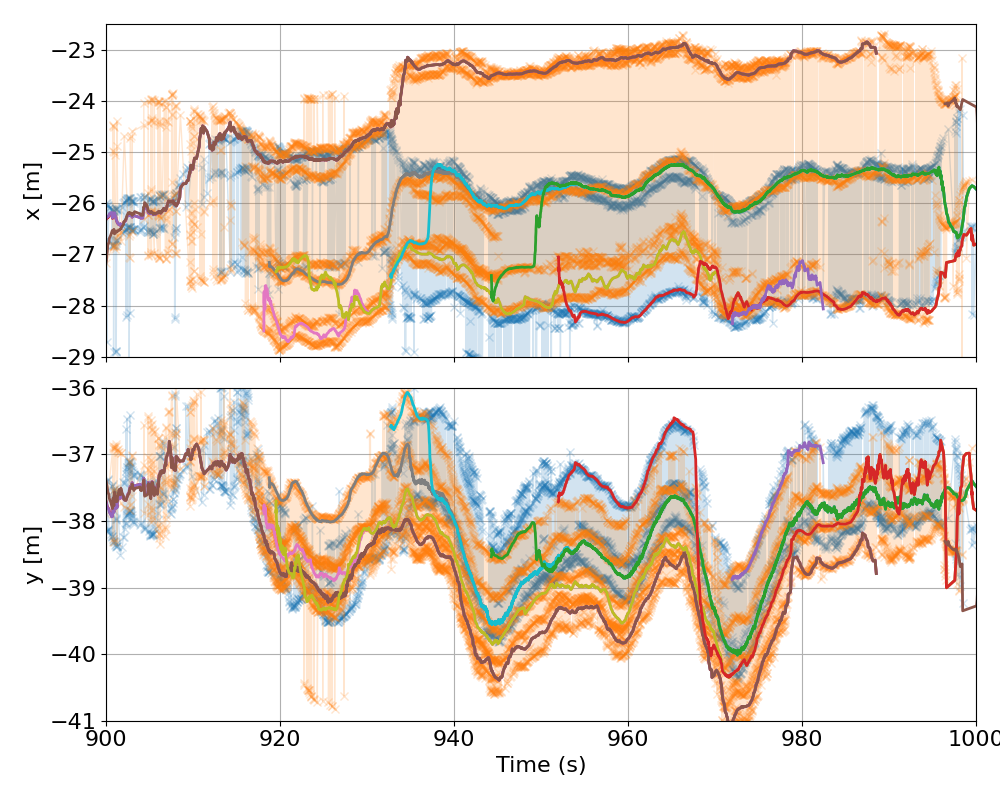

In [28]:
coords = ['x', 'y']  # Coordinates to plot
## pos tracker plot with gt and measurements
fig_proj_tracks = pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], label="proj 1", alpha=0.2, marker='x', noisy_limits=True, coords=coords)
pu.plot_xyz_over_time(topic_data["/machine_2/object_detections/projected_to_world"], fig=fig_proj_tracks, label="proj 2", alpha=0.2, marker='x', noisy_limits=True, coords=coords) 

linestyles  = ['-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.', '-', '--', ':', '-.']
tab_colors = ['tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
for i, track_df in enumerate(results):
    pu.plot_xyz_over_time(track_df, fig=fig_proj_tracks, label=f"Track {i+1}", linewidth=2.0, coords=coords, color=tab_colors[i % len(tab_colors)])

handles, labels = fig_proj_tracks.axes[0].get_legend_handles_labels()
# fig_proj_tracks.legend(handles, labels, loc='upper right')
# fig_proj_tracks.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.925))
# fig_proj_tracks.suptitle(\\JPDA position Tracking - GT with Tracks\\)
fig_proj_tracks.set_size_inches(10, 8)
fig_proj_tracks.tight_layout(rect=[0, 0, 1.0, 1.0])
fig_proj_tracks.align_ylabels()

# custom y-axis limits
fig_proj_tracks.axes[0].set_ylim((-29, -22.5))
fig_proj_tracks.axes[1].set_ylim((-41, -36))
# fig_proj_tracks.axes[2].set_ylim((-4.0, 1.0))

# custom x-axis limits
for ax in fig_proj_tracks.axes:
    ax.set_xlim((900, 1000))

In [29]:
# fig_proj_tracks.savefig(os.path.join(PLOTS_DIR, "proj_tracking_mn_gate1.5_PD0.3_donkey_xy.svg"), dpi=600, bbox_inches='tight')

### Single-MAV JPDA Tracking with Distributed Tracks

Process each MAV's data separately using individual JPDA trackers, and combine the tracks in one plot.

In [30]:
# Initialize separate JPDA trackers for each MAV
individual_trackers = {}
individual_results = {}
# configuration file for the tracker (otherwise it will use the default one)

for mav_id in [1, 2]:
    logger.info(f"Processing MAV {mav_id} data individually")
    
    # Get data for this specific MAV
    topic = f"/machine_{mav_id}/object_detections/projected_to_world"
    projected_df = topic_data[topic].copy()
    
    # Cut data to time range of interest
    projected_df = projected_df[(projected_df['time'] >= start_time) & (projected_df['time'] <= end_time)]
    
    # Convert to measurements format
    proj_time, proj_measurements = dfu.dataframe_to_measurements(projected_df)
    
    # Group measurements by timestamp
    measurements_by_time = defaultdict(list)
    for time, meas in zip(proj_time, proj_measurements):
        rounded_time = round(time * 30) / 30
        measurements_by_time[rounded_time].append(meas)
    
    # Convert to measurement groups
    proj_data = []
    for timestamp in sorted(measurements_by_time.keys()):
        meas = np.array(measurements_by_time[timestamp], dtype=object)
        proj_data.append((timestamp, meas, mav_id))
    
    logger.info(f"MAV {mav_id}: Grouped {len(proj_measurements)} measurements into {len(proj_data)} frames")
    
    # Initialize individual JPDA tracker
    individual_gater = mtt.MahalanobisGater()
    individual_mh_likelihood = mtt.MahalanobisLikelihood()
    individual_filter = mtt.KFTrack()
    individual_mn_logic = mtt.MNLogic()
    
    individual_tracker = mtt.JPDATracker(
        filter_obj=individual_filter,
        gater=individual_gater,
        likelihood=individual_mh_likelihood,
        track_logic=individual_mn_logic,
        drone_id=None,
    )
    
    # Process measurements
    for measurements in tqdm.tqdm(proj_data, desc=f"Tracking MAV {mav_id} individually"):
        individual_tracker.evaluate(measurements)
    
    # Extract confirmed tracks
    confirmed_tracks = [track for track in individual_tracker.tracks 
                       if track.stage == mtt.TrackStage.CONFIRMED or track.stage == mtt.TrackStage.ARCHIVED]
    
    logger.info(f"MAV {mav_id}: {len(confirmed_tracks)} confirmed tracks out of {len(individual_tracker.tracks)} total tracks")
    
    # Convert to dataframes
    track_results = [dfu.track_to_dataframe(track) for track in confirmed_tracks]
    
    individual_trackers[mav_id] = individual_tracker
    individual_results[mav_id] = track_results

print("Individual MAV tracking completed")

INFO: Processing MAV 1 data individually
INFO: MAV 1: Grouped 5319 measurements into 2614 frames
Tracking MAV 1 individually: 100%|██████████| 2614/2614 [00:04<00:00, 586.57it/s]
INFO: MAV 1: 4 confirmed tracks out of 4 total tracks
INFO: Processing MAV 2 data individually
INFO: MAV 2: Grouped 10829 measurements into 2873 frames
Tracking MAV 2 individually: 100%|██████████| 2873/2873 [00:22<00:00, 130.25it/s]
INFO: MAV 2: 13 confirmed tracks out of 13 total tracks


Individual MAV tracking completed


### Single-MAV JPDA Tracking with Distributed Tracks - Plots

Create a combined plot showing the tracking results from individual MAV JPDA trackers, similar to the JPDA node notebook.

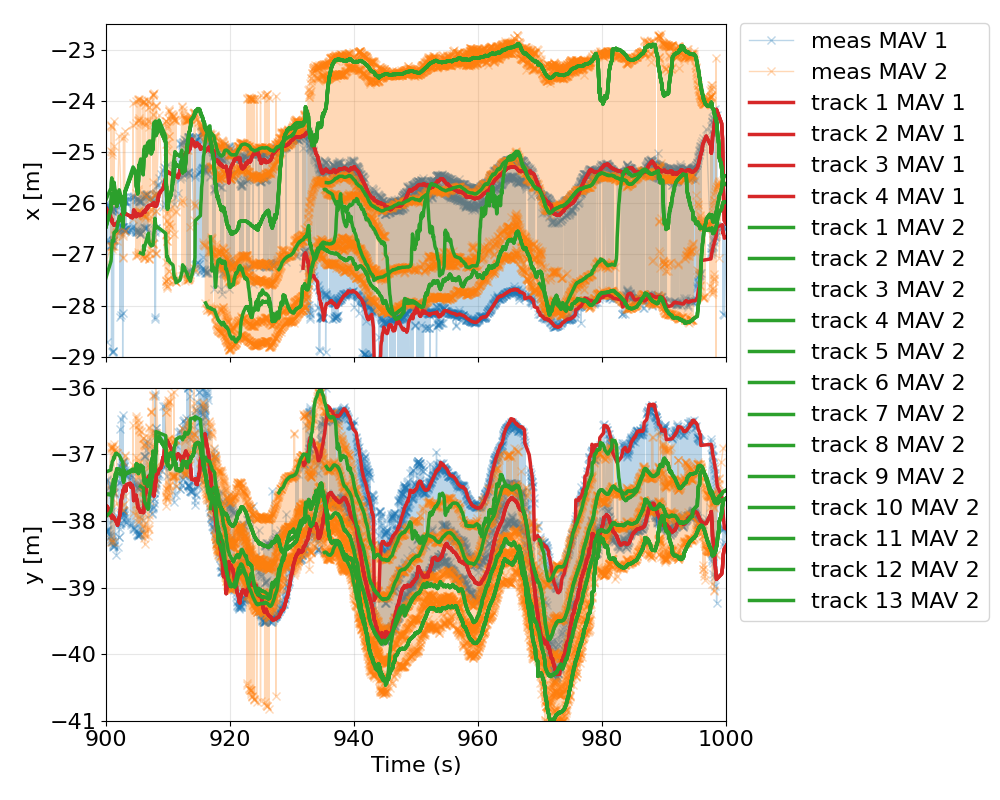

In [31]:
coords = ['x', 'y']  # Coordinates to plot

# Create combined individual MAV tracking plot
fig_individual = pu.plot_xyz_over_time(
    topic_data["/machine_1/object_detections/projected_to_world"], 
    label="meas MAV 1", 
    alpha=0.3, 
    marker='x', 
    coords=coords,
    noisy_limits=True
)

pu.plot_xyz_over_time(
    topic_data["/machine_2/object_detections/projected_to_world"], 
    fig=fig_individual, 
    label="meas MAV 2", 
    alpha=0.3, 
    marker='x', 
    coords=coords,
    noisy_limits=True
)

# Define colors for tracks from different MAVs
mav_colors = {1: ['tab:red'], 2: ['tab:green']}

# Add individual tracking results with different colors for each MAV and track
for mav_id in [1, 2]:
    tracks = individual_results[mav_id]
    colors = mav_colors[mav_id]
    
    for j, track_df in enumerate(tracks):
        color = colors[j % len(colors)]
        pu.plot_xyz_over_time(
            track_df, 
            fig=fig_individual, 
            label=f"track {j+1} MAV {mav_id}", 
            coords=coords, 
            linewidth=2.5,
            color=color,
            noisy_limits=True,
        )

handles, labels = fig_individual.axes[0].get_legend_handles_labels()
fig_individual.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.985))
fig_individual.set_size_inches(10, 8)
fig_individual.tight_layout(rect=[0, 0, 0.75, 1.0])

# Custom axis limits (same as previous plots)
fig_individual.axes[0].set_ylim((-29, -22.5))
fig_individual.axes[1].set_ylim((-41, -36))

# Custom x-axis limits
for ax in fig_individual.axes:
    ax.set_xlim((900, 1000))
    ax.grid(True, alpha=0.3)

plt.show()

In [32]:
# Save the individual MAV tracking results plot
# fig_individual.savefig(os.path.join(PLOTS_DIR, "individual_mav_jpda_tracking_donkey_xy.svg"), dpi=600, bbox_inches='tight')